<a href="https://colab.research.google.com/github/PredictiveHealth-AI/hospital-patient-readmission-prediction/blob/Demo-Main/notebooks/Group8_Readmission_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
import os

for root, dirs, files in os.walk("/"):
    if "diabetic_data.csv" in files:
        print("File found at:", os.path.join(root, "diabetic_data.csv"))


File found at: /content/drive/MyDrive/Machine learing project/diabetes+130-us+hospitals+for+years+1999-2008/diabetic_data.csv


In [ ]:
dataset_path = "/content/drive/MyDrive/Machine learing project/diabetes+130-us+hospitals+for+years+1999-2008/diabetic_data.csv"

df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Dataset loaded successfully!
Dataset Shape: (101766, 50)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

In [ ]:
print(df["readmitted"].value_counts())

print("\nReadmission percentages:")
print(
    df["readmitted"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

Readmission percentages:
readmitted
NO     53.91
>30    34.93
<30    11.16
Name: proportion, dtype: float64


In [ ]:
print("Missing values per column:")
print(df.isna().sum().sort_values(ascending=False).head(15))

print("\nQuestion mark values:")
print((df == "?").sum().sort_values(ascending=False).head(15))


Missing values per column:
max_glu_serum               96420
A1Cresult                   84748
race                            0
gender                          0
age                             0
weight                          0
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                      0
medical_specialty               0
num_lab_procedures              0
num_procedures                  0
num_medications                 0
dtype: int64

Question mark values:
weight                 98569
medical_specialty      49949
payer_code             40256
race                    2273
diag_3                  1423
diag_2                   358
diag_1                    21
admission_type_id          0
patient_nbr                0
encounter_id               0
time_in_hospital           0
admission_source_id        0
num_lab_procedures         0
num_procedures             0
num_medications      

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    if 'diabetic_data.csv' in files:
        print("Dataset:", os.path.join(root, 'diabetic_data.csv'))

Dataset: /content/drive/MyDrive/Machine learing project/diabetes+130-us+hospitals+for+years+1999-2008/diabetic_data.csv


In [ ]:
import pandas as pd
import os

dataset_path = "/content/drive/MyDrive/Machine learing project/diabetes+130-us+hospitals+for+years+1999-2008/diabetic_data.csv"

df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Dataset loaded successfully!
Dataset Shape: (101766, 50)


In [ ]:
print(df["readmitted"].value_counts())

print("\nPercentage:")
print(
    df["readmitted"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

Percentage:
readmitted
NO     53.91
>30    34.93
<30    11.16
Name: proportion, dtype: float64


In [ ]:
import seaborn as sns

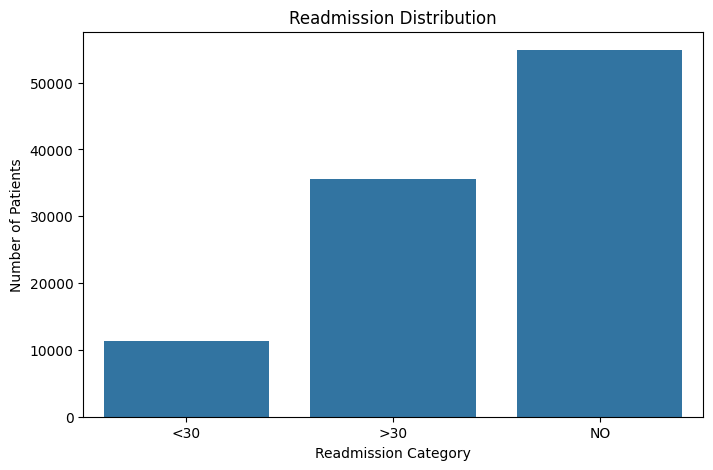

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="readmitted",
    order=["<30", ">30", "NO"]
)

plt.title("Readmission Distribution")
plt.xlabel("Readmission Category")
plt.ylabel("Number of Patients")
plt.show()

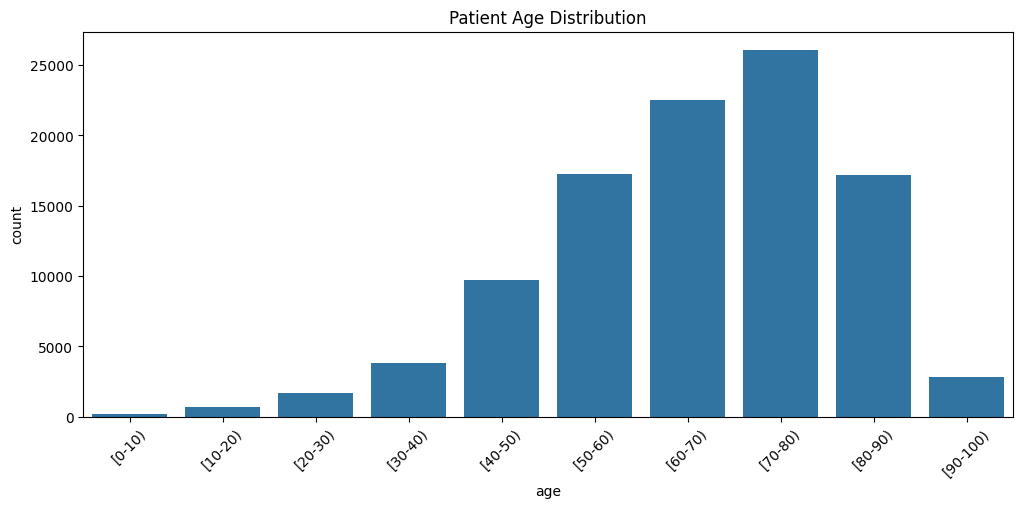

In [ ]:
plt.figure(figsize=(12, 5))

sns.countplot(
    data=df,
    x="age",
    order=sorted(df["age"].unique())
)

plt.title("Patient Age Distribution")
plt.xticks(rotation=45)
plt.show()

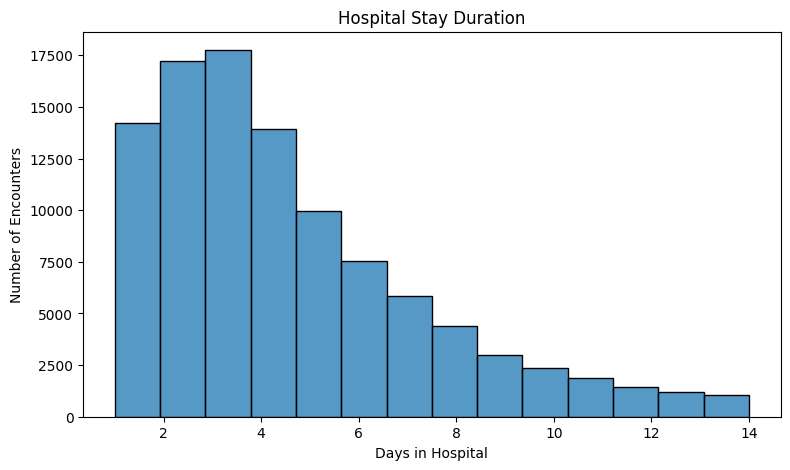

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="time_in_hospital",
    bins=14
)

plt.title("Hospital Stay Duration")
plt.xlabel("Days in Hospital")
plt.ylabel("Number of Encounters")
plt.show()

In [ ]:
visit_columns = [
    "number_outpatient",
    "number_emergency",
    "number_inpatient"
]

print(df[visit_columns].describe())

       number_outpatient  number_emergency  number_inpatient
count      101766.000000     101766.000000     101766.000000
mean            0.369357          0.197836          0.635566
std             1.267265          0.930472          1.262863
min             0.000000          0.000000          0.000000
25%             0.000000          0.000000          0.000000
50%             0.000000          0.000000          0.000000
75%             0.000000          0.000000          1.000000
max            42.000000         76.000000         21.000000


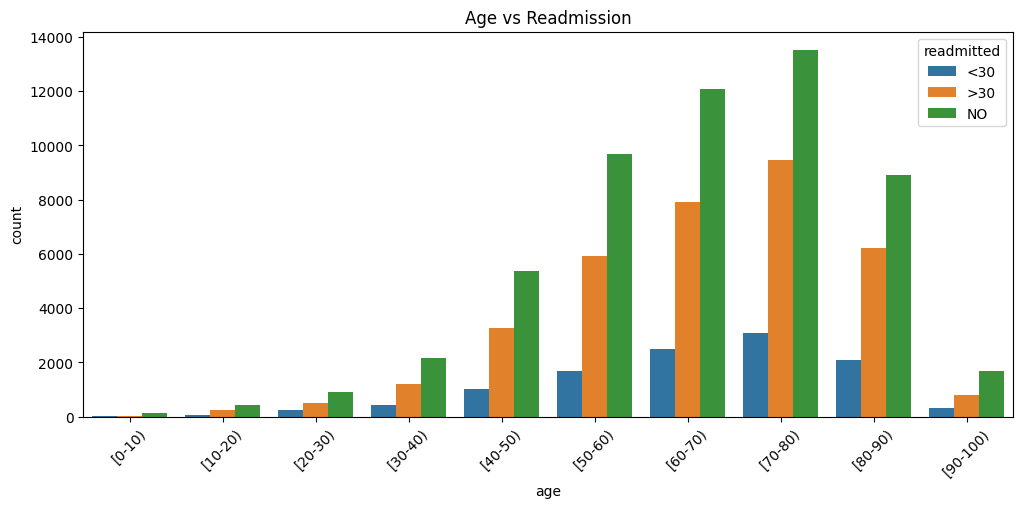

In [ ]:
plt.figure(figsize=(12, 5))

sns.countplot(
    data=df,
    x="age",
    hue="readmitted",
    hue_order=["<30", ">30", "NO"]
)

plt.title("Age vs Readmission")
plt.xticks(rotation=45)
plt.show()

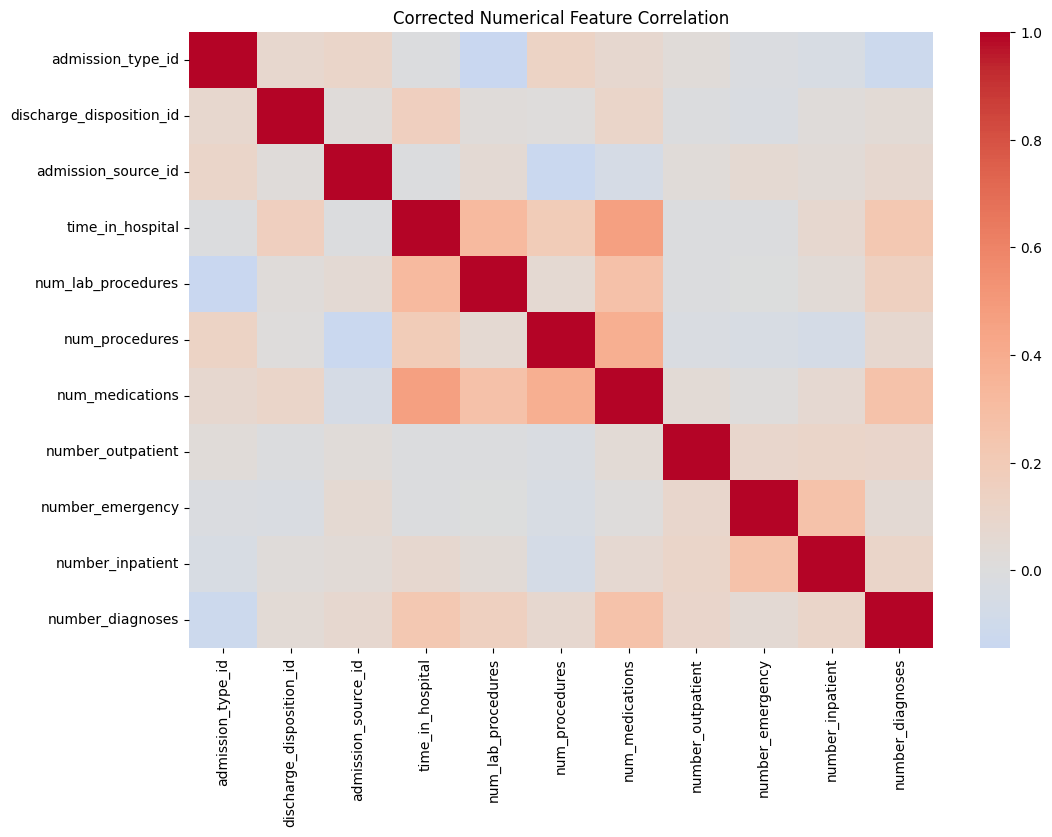

In [ ]:
exclude_columns = [
    "encounter_id",
    "patient_nbr"
]

numeric_df = df.select_dtypes(
    include="number"
).drop(columns=exclude_columns, errors="ignore")

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Corrected Numerical Feature Correlation")

plt.show()

In [ ]:
import os

os.makedirs("results", exist_ok=True)

df["readmitted"].value_counts().to_csv(
    "results/readmission_distribution.csv"
)

print("EDA results saved!")

EDA results saved!


In [ ]:
age_readmission = pd.crosstab(
    df["age"],
    df["readmitted"],
    normalize="index"
) * 100

print(age_readmission.round(2))

readmitted    <30    >30     NO
age                            
[0-10)       1.86  16.15  81.99
[10-20)      5.79  32.42  61.79
[20-30)     14.24  30.78  54.98
[30-40)     11.23  31.44  57.32
[40-50)     10.60  33.85  55.55
[50-60)      9.67  34.29  56.04
[60-70)     11.13  35.12  53.75
[70-80)     11.77  36.35  51.88
[80-90)     12.08  36.19  51.73
[90-100)    11.10  28.93  59.97


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

dataset_path = "/content/drive/MyDrive/Machine learing project/diabetes+130-us+hospitals+for+years+1999-2008/diabetic_data.csv"

df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset loaded successfully!
Dataset Shape: (101766, 50)


In [ ]:
df["readmitted_30"] = df["readmitted"].map({
    "<30": 1,
    ">30": 0,
    "NO": 0
})

print(df[["readmitted", "readmitted_30"]].head(10))

  readmitted  readmitted_30
0         NO              0
1        >30              0
2         NO              0
3         NO              0
4         NO              0
5        >30              0
6         NO              0
7        >30              0
8         NO              0
9         NO              0


In [ ]:
print(df["readmitted_30"].value_counts(dropna=False))

readmitted_30
0    90409
1    11357
Name: count, dtype: int64


In [ ]:
assert df["readmitted_30"].notna().all()

print("Target creation successful!")

Target creation successful!


In [ ]:
target_counts = df["readmitted_30"].value_counts()

target_percentage = (
    df["readmitted_30"]
    .value_counts(normalize=True) * 100
)

print("Class Counts:")
print(target_counts)

print("\nClass Percentages:")
print(target_percentage.round(2))

Class Counts:
readmitted_30
0    90409
1    11357
Name: count, dtype: int64

Class Percentages:
readmitted_30
0    88.84
1    11.16
Name: proportion, dtype: float64


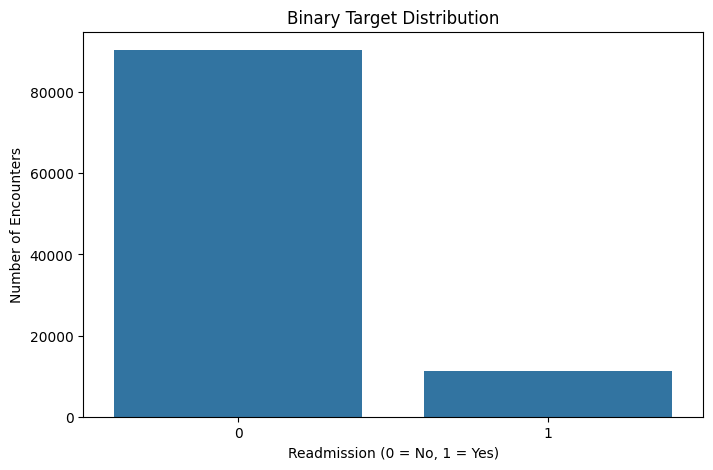

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="readmitted_30"
)

plt.title("Binary Target Distribution")
plt.xlabel("Readmission (0 = No, 1 = Yes)")
plt.ylabel("Number of Encounters")

plt.show()

In [ ]:
# Target variable
y = df["readmitted_30"]

# Patient ID and encounter ID are identifiers, not predictive features
X = df.drop(
    columns=[
        "readmitted",
        "readmitted_30",
        "encounter_id",
        "patient_nbr"
    ]
)

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (101766, 47)
Target Shape: (101766,)


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

groups = df["patient_nbr"]

In [ ]:
gss_test = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_val_idx, test_idx = next(
    gss_test.split(X, y, groups=groups)
)

In [ ]:
gss_val = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_rel_idx, val_rel_idx = next(
    gss_val.split(
        X.iloc[train_val_idx],
        y.iloc[train_val_idx],
        groups=groups.iloc[train_val_idx]
    )
)

train_idx = train_val_idx[train_rel_idx]
val_idx = train_val_idx[val_rel_idx]

In [ ]:
X_train = X.iloc[train_idx].copy()
X_val = X.iloc[val_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_val = y.iloc[val_idx].copy()
y_test = y.iloc[test_idx].copy()

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (65146, 47)
Validation: (16467, 47)
Testing: (20153, 47)


In [ ]:
train_patients = set(groups.iloc[train_idx])
val_patients = set(groups.iloc[val_idx])
test_patients = set(groups.iloc[test_idx])

print("Train-Val Overlap:",
      len(train_patients & val_patients))

print("Train-Test Overlap:",
      len(train_patients & test_patients))

print("Val-Test Overlap:",
      len(val_patients & test_patients))

Train-Val Overlap: 0
Train-Test Overlap: 0
Val-Test Overlap: 0


In [ ]:
print("Training Class Distribution:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nValidation Class Distribution:")
print((y_val.value_counts(normalize=True) * 100).round(2))

print("\nTesting Class Distribution:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training Class Distribution:
readmitted_30
0    88.75
1    11.25
Name: proportion, dtype: float64

Validation Class Distribution:
readmitted_30
0    88.6
1    11.4
Name: proportion, dtype: float64

Testing Class Distribution:
readmitted_30
0    89.33
1    10.67
Name: proportion, dtype: float64


In [ ]:
import os

PROJECT_PATH = "/content/drive/MyDrive/Machine learing project"

folders = [
    "processed_data",
    "models",
    "results",
    "notebooks",
    "reports",
    "presentation"
]

for folder in folders:
    os.makedirs(
        os.path.join(PROJECT_PATH, folder),
        exist_ok=True
    )

print("Project folders created successfully!")

Project folders created successfully!


In [ ]:
print("splits exists:", "splits" in globals())

print("Available split variables:")

for name in globals():
    if "split" in name.lower():
        print(name)

splits exists: False
Available split variables:
GroupShuffleSplit


In [ ]:
for name in globals():
    if any(word in name.lower() for word in ["train", "test", "val", "split"]):
        print(name)

GroupShuffleSplit
gss_test
train_val_idx
test_idx
gss_val
train_rel_idx
val_rel_idx
train_idx
val_idx
X_train
X_val
X_test
y_train
y_val
y_test
train_patients
val_patients
test_patients


In [ ]:
splits = {
    "X_train": X_train,
    "X_val": X_val,
    "X_test": X_test,
    "y_train": y_train,
    "y_val": y_val,
    "y_test": y_test,
    "train_idx": train_idx,
    "val_idx": val_idx,
    "test_idx": test_idx
}

print("Splits dictionary created successfully!")

for name, data in splits.items():
    print(name, data.shape)

Splits dictionary created successfully!
X_train (65146, 47)
X_val (16467, 47)
X_test (20153, 47)
y_train (65146,)
y_val (16467,)
y_test (20153,)
train_idx (65146,)
val_idx (16467,)
test_idx (20153,)


In [ ]:
import os
import joblib

save_path = os.path.join(
    PROJECT_PATH,
    "processed_data",
    "day3_splits.joblib"
)

joblib.dump(splits, save_path)

print("Day 3 datasets saved successfully!")
print("Saved location:", save_path)

Day 3 datasets saved successfully!
Saved location: /content/drive/MyDrive/Machine learing project/processed_data/day3_splits.joblib


In [ ]:
print("File exists:", os.path.exists(save_path))

print(
    "File size:",
    round(os.path.getsize(save_path) / (1024 * 1024), 2),
    "MB"
)

File exists: True
File size: 29.83 MB


In [ ]:
import joblib

loaded_splits = joblib.load(save_path)

print("Saved splits loaded successfully!")

for name, data in loaded_splits.items():
    print(name, data.shape)

Saved splits loaded successfully!
X_train (65146, 47)
X_val (16467, 47)
X_test (20153, 47)
y_train (65146,)
y_val (16467,)
y_test (20153,)
train_idx (65146,)
val_idx (16467,)
test_idx (20153,)


In [ ]:
import os

print("File exists:", os.path.exists(save_path))
print("File size:", round(os.path.getsize(save_path) / (1024 * 1024), 2), "MB")

File exists: True
File size: 29.83 MB


In [ ]:
PROJECT_PATH = "/content/drive/MyDrive/Machine learing project"

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

PROJECT_PATH = "/content/drive/MyDrive/Machine learing project"

dataset_path = os.path.join(
    PROJECT_PATH,
    "diabetes+130-us+hospitals+for+years+1999-2008",
    "diabetic_data.csv"
)

df = pd.read_csv(dataset_path)

print("Original dataset:", df.shape)

Original dataset: (101766, 50)


In [ ]:
split_path = os.path.join(
    PROJECT_PATH,
    "processed_data",
    "day3_splits.joblib"
)

splits = joblib.load(split_path)

X_train = splits["X_train"]
X_val = splits["X_val"]
X_test = splits["X_test"]

y_train = splits["y_train"]
y_val = splits["y_val"]
y_test = splits["y_test"]

print("Day 3 data loaded successfully!")


Day 3 data loaded successfully!


In [ ]:
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nTarget shapes:")

print("y_train:", y_train.shape)
print("y_val:", y_val.shape)
print("y_test:", y_test.shape)


Training: (65146, 47)
Validation: (16467, 47)
Testing: (20153, 47)

Target shapes:
y_train: (65146,)
y_val: (16467,)
y_test: (20153,)


In [ ]:
train_patients = set(
    df.loc[X_train.index, "patient_nbr"].dropna().unique()
)

val_patients = set(
    df.loc[X_val.index, "patient_nbr"].dropna().unique()
)

test_patients = set(
    df.loc[X_test.index, "patient_nbr"].dropna().unique()
)

print("Train-Val Overlap:",
      len(train_patients & val_patients))

print("Train-Test Overlap:",
      len(train_patients & test_patients))

print("Val-Test Overlap:",
      len(val_patients & test_patients))

Train-Val Overlap: 0
Train-Test Overlap: 0
Val-Test Overlap: 0


In [ ]:
def check_distribution(name, y):

    print("\n", name)

    counts = y.value_counts().sort_index()

    percentages = (
        y.value_counts(normalize=True)
        .sort_index() * 100
    )

    print("Counts:")
    print(counts)

    print("\nPercentages:")
    print(percentages.round(2))


check_distribution("Training", y_train)

check_distribution("Validation", y_val)

check_distribution("Testing", y_test)


 Training
Counts:
readmitted_30
0    57817
1     7329
Name: count, dtype: int64

Percentages:
readmitted_30
0    88.75
1    11.25
Name: proportion, dtype: float64

 Validation
Counts:
readmitted_30
0    14590
1     1877
Name: count, dtype: int64

Percentages:
readmitted_30
0    88.6
1    11.4
Name: proportion, dtype: float64

 Testing
Counts:
readmitted_30
0    18002
1     2151
Name: count, dtype: int64

Percentages:
readmitted_30
0    89.33
1    10.67
Name: proportion, dtype: float64


In [ ]:
X_train_clean = X_train.replace("?", np.nan)

missing_count = X_train_clean.isnull().sum()

missing_percentage = (
    X_train_clean.isnull().mean() * 100
)

missing_summary = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": missing_percentage
})

missing_summary = missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
)

print(missing_summary[missing_summary["Missing_Count"] > 0])

                   Missing_Count  Missing_Percentage
weight                     63051           96.784146
max_glu_serum              61633           94.607497
A1Cresult                  54253           83.279096
medical_specialty          31876           48.930095
payer_code                 25823           39.638658
race                        1469            2.254935
diag_3                       902            1.384582
diag_2                       249            0.382218
diag_1                        11            0.016885


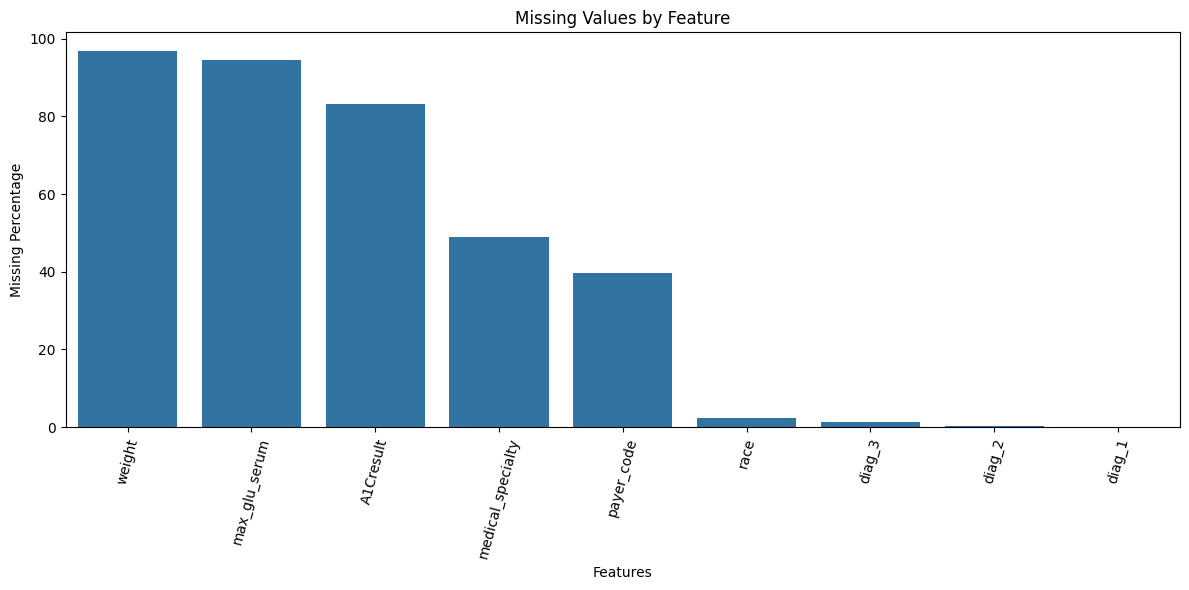

In [ ]:
missing_data = missing_summary[
    missing_summary["Missing_Count"] > 0
]

plt.figure(figsize=(12, 6))

sns.barplot(
    data=missing_data.reset_index(),
    x="index",
    y="Missing_Percentage"
)

plt.title("Missing Values by Feature")
plt.xlabel("Features")
plt.ylabel("Missing Percentage")

plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

In [ ]:
numeric_features = X_train_clean.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train_clean.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:", len(numeric_features))

print("\nCategorical Features:", len(categorical_features))

print("\nNumerical Columns:")
print(numeric_features)

print("\nCategorical Columns:")
print(categorical_features)

Numerical Features: 11

Categorical Features: 36

Numerical Columns:
['admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']

Categorical Columns:
['race', 'gender', 'age', 'weight', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed']


In [ ]:
X_val_clean = X_val.replace("?", np.nan)

X_test_clean = X_test.replace("?", np.nan)

In [ ]:
cleaned_splits = {
    "X_train": X_train_clean,
    "X_val": X_val_clean,
    "X_test": X_test_clean,
    "y_train": y_train,
    "y_val": y_val,
    "y_test": y_test
}

save_path = os.path.join(
    PROJECT_PATH,
    "processed_data",
    "day4_cleaned_splits.joblib"
)

joblib.dump(cleaned_splits, save_path)

print("Day 4 cleaned data saved successfully!")

print("Location:", save_path)

print("File exists:", os.path.exists(save_path))

Day 4 cleaned data saved successfully!
Location: /content/drive/MyDrive/Machine learing project/processed_data/day4_cleaned_splits.joblib
File exists: True


In [ ]:
check_columns = [
    "weight",
    "max_glu_serum",
    "A1Cresult",
    "medical_specialty",
    "payer_code"
]

for col in check_columns:

    print("\n", "=" * 40)
    print("Column:", col)

    print(
        df[col]
        .value_counts(dropna=False)
        .head(10)
    )


Column: weight
weight
?            98569
[75-100)      1336
[50-75)        897
[100-125)      625
[125-150)      145
[25-50)         97
[0-25)          48
[150-175)       35
[175-200)       11
>200             3
Name: count, dtype: int64

Column: max_glu_serum
max_glu_serum
NaN     96420
Norm     2597
>200     1485
>300     1264
Name: count, dtype: int64

Column: A1Cresult
A1Cresult
NaN     84748
>8       8216
Norm     4990
>7       3812
Name: count, dtype: int64

Column: medical_specialty
medical_specialty
?                             49949
InternalMedicine              14635
Emergency/Trauma               7565
Family/GeneralPractice         7440
Cardiology                     5352
Surgery-General                3099
Nephrology                     1613
Orthopedics                    1400
Orthopedics-Reconstructive     1233
Radiologist                    1140
Name: count, dtype: int64

Column: payer_code
payer_code
?     40256
MC    32439
HM     6274
SP     5007
BC     4655
MD     35

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import joblib
import os

import sklearn

print("Scikit-learn Version:", sklearn.__version__)

Scikit-learn Version: 1.6.1


In [ ]:
PROJECT_PATH = "/content/drive/MyDrive/Machine learing project"

dataset_path = os.path.join(
    PROJECT_PATH,
    "diabetes+130-us+hospitals+for+years+1999-2008",
    "diabetic_data.csv"
)

day4_path = os.path.join(
    PROJECT_PATH,
    "processed_data",
    "day4_cleaned_splits.joblib"
)

In [ ]:
day4 = joblib.load(day4_path)

X_train_previous = day4["X_train"]
X_val_previous = day4["X_val"]
X_test_previous = day4["X_test"]

y_train = day4["y_train"]
y_val = day4["y_val"]
y_test = day4["y_test"]

print("Day 4 data loaded successfully!")

Day 4 data loaded successfully!


In [ ]:
df_raw = pd.read_csv(
    dataset_path,
    keep_default_na=False
)

print("Original Dataset:", df_raw.shape)

Original Dataset: (101766, 50)


In [ ]:
def rebuild_clean_split(previous_X):

    X = df_raw.loc[
        previous_X.index,
        previous_X.columns
    ].copy()

    # Actual missing placeholders
    X = X.replace({
        "?": np.nan,
        "": np.nan
    })

    # Preserve laboratory test information
    lab_columns = [
        "max_glu_serum",
        "A1Cresult"
    ]

    for col in lab_columns:

        X[col] = X[col].replace(
            "None",
            "Not_Measured"
        )

    return X

In [ ]:
X_train_clean = rebuild_clean_split(
    X_train_previous
)

X_val_clean = rebuild_clean_split(
    X_val_previous
)

X_test_clean = rebuild_clean_split(
    X_test_previous
)

print("Original categorical values restored!")

Original categorical values restored!


In [ ]:
for col in ["max_glu_serum", "A1Cresult"]:

    print("\nColumn:", col)

    print(
        X_train_clean[col].value_counts(
            dropna=False
        )
    )


Column: max_glu_serum
max_glu_serum
Not_Measured    61633
Norm             1703
>200              981
>300              829
Name: count, dtype: int64

Column: A1Cresult
A1Cresult
Not_Measured    54253
>8               5260
Norm             3171
>7               2462
Name: count, dtype: int64


In [ ]:
for X in [
    X_train_clean,
    X_val_clean,
    X_test_clean
]:

    X["weight_recorded"] = (
        X["weight"]
        .notna()
        .astype(int)
    )

    X.drop(
        columns=["weight"],
        inplace=True
    )

print("Weight feature processed!")

Weight feature processed!


In [ ]:
id_categorical = [
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id"
]

numeric_features = [
    col for col in
    X_train_clean.select_dtypes(
        include=np.number
    ).columns
    if col not in id_categorical
]

categorical_features = [
    col for col in X_train_clean.columns
    if col not in numeric_features
]

print("Numerical Features:", len(numeric_features))

print("Categorical Features:", len(categorical_features))

Numerical Features: 9
Categorical Features: 38


In [ ]:
for X in [
    X_train_clean,
    X_val_clean,
    X_test_clean
]:

    for col in categorical_features:

        X[col] = X[col].map(
            lambda value:
                np.nan if pd.isna(value)
                else str(value)
        )

print("Categorical features converted to strings!")

Categorical features converted to strings!


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline

numeric_pipeline = Pipeline(
    steps=[

        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),

        (
            "scaler",
            StandardScaler()
        )

    ]
)

In [ ]:
from sklearn.impute import SimpleImputer

from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline(
    steps=[

        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Unknown"
            )
        ),

        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=20,
                sparse_output=True
            )
        )

    ]
)

In [ ]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(

    transformers=[

        (
            "num",
            numeric_pipeline,
            numeric_features
        ),

        (
            "cat",
            categorical_pipeline,
            categorical_features
        )

    ],

    remainder="drop"

)

In [ ]:
# Fit and transform training data

X_train_processed = preprocessor.fit_transform(
    X_train_clean
)

# Transform validation data

X_val_processed = preprocessor.transform(
    X_val_clean
)

# Transform testing data

X_test_processed = preprocessor.transform(
    X_test_clean
)

print("Preprocessing completed!")

Preprocessing completed!


In [ ]:
print(
    "Training Shape:",
    X_train_processed.shape
)

print(
    "Validation Shape:",
    X_val_processed.shape
)

print(
    "Testing Shape:",
    X_test_processed.shape
)

Training Shape: (65146, 937)
Validation Shape: (16467, 937)
Testing Shape: (20153, 937)


In [ ]:
from scipy import sparse

print(
    "Is Sparse Matrix:",
    sparse.issparse(X_train_processed)
)

Is Sparse Matrix: True


In [ ]:
def check_nan(matrix):

    if sparse.issparse(matrix):

        return np.isnan(
            matrix.data
        ).any()

    return np.isnan(matrix).any()


print(
    "Training contains NaN:",
    check_nan(X_train_processed)
)

print(
    "Validation contains NaN:",
    check_nan(X_val_processed)
)

print(
    "Testing contains NaN:",
    check_nan(X_test_processed)
)

Training contains NaN: False
Validation contains NaN: False
Testing contains NaN: False


In [ ]:
processed_path = os.path.join(
    PROJECT_PATH,
    "processed_data"
)

models_path = os.path.join(
    PROJECT_PATH,
    "models"
)

os.makedirs(processed_path, exist_ok=True)
os.makedirs(models_path, exist_ok=True)

In [ ]:
feature_names = preprocessor.get_feature_names_out()

day5_artifacts = {

    "X_train_processed": X_train_processed,

    "X_val_processed": X_val_processed,

    "X_test_processed": X_test_processed,

    "y_train": y_train,

    "y_val": y_val,

    "y_test": y_test,

    "feature_names": feature_names,

    "numeric_features": numeric_features,

    "categorical_features": categorical_features

}

In [ ]:
day5_save_path = os.path.join(
    processed_path,
    "day5_preprocessed_splits.joblib"
)

joblib.dump(
    day5_artifacts,
    day5_save_path,
    compress=3
)

print("Day 5 processed data saved!")

Day 5 processed data saved!


In [ ]:
preprocessor_save_path = os.path.join(
    models_path,
    "preprocessor.joblib"
)

joblib.dump(
    preprocessor,
    preprocessor_save_path,
    compress=3
)

print("Preprocessing pipeline saved!")

Preprocessing pipeline saved!


In [ ]:
print(
    "Processed data exists:",
    os.path.exists(day5_save_path)
)

print(
    "Preprocessor exists:",
    os.path.exists(preprocessor_save_path)
)

print(
    "Processed file size:",
    round(
        os.path.getsize(day5_save_path) / (1024 * 1024),
        2
    ),
    "MB"
)

Processed data exists: True
Preprocessor exists: True
Processed file size: 3.89 MB


In [ ]:
df_raw = pd.read_csv(
    dataset_path,
    keep_default_na=False
)

print("Original Dataset:", df_raw.shape)

Original Dataset: (101766, 50)


In [ ]:
def rebuild_clean_split(previous_X):

    X = df_raw.loc[
        previous_X.index,
        previous_X.columns
    ].copy()

    X = X.replace({
        "?": np.nan,
        "": np.nan
    })

    lab_columns = [
        "max_glu_serum",
        "A1Cresult"
    ]

    for col in lab_columns:

        X[col] = X[col].replace(
            "None",
            "Not_Measured"
        )

    return X

In [ ]:
X_train_clean = rebuild_clean_split(X_train_previous)

X_val_clean = rebuild_clean_split(X_val_previous)

X_test_clean = rebuild_clean_split(X_test_previous)

In [ ]:
for col in ["max_glu_serum", "A1Cresult"]:

    print("\nColumn:", col)

    print(
        X_train_clean[col].value_counts(
            dropna=False
        )
    )


Column: max_glu_serum
max_glu_serum
Not_Measured    61633
Norm             1703
>200              981
>300              829
Name: count, dtype: int64

Column: A1Cresult
A1Cresult
Not_Measured    54253
>8               5260
Norm             3171
>7               2462
Name: count, dtype: int64


In [ ]:
for X in [
    X_train_clean,
    X_val_clean,
    X_test_clean
]:

    X["weight_recorded"] = (
        X["weight"].notna().astype(int)
    )

    X.drop(
        columns=["weight"],
        inplace=True
    )

print("Weight feature engineering completed!")

Weight feature engineering completed!


In [ ]:
constant_features = [
    col for col in X_train_clean.columns
    if X_train_clean[col].nunique(dropna=True) <= 1
]

print("Constant Features:", constant_features)

Constant Features: ['acetohexamide', 'examide', 'citoglipton', 'glimepiride-pioglitazone', 'metformin-pioglitazone']


In [ ]:
for X in [
    X_train_clean,
    X_val_clean,
    X_test_clean
]:

    X.drop(
        columns=constant_features,
        inplace=True
    )

print("Constant features removed!")

Constant features removed!


In [ ]:
id_categorical = [
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id"
]

numeric_features = [
    col for col in
    X_train_clean.select_dtypes(
        include=np.number
    ).columns
    if col not in id_categorical
]

categorical_features = [
    col for col in X_train_clean.columns
    if col not in numeric_features
]

print("Numerical Features:", len(numeric_features))

print("Categorical Features:", len(categorical_features))

print("\nNumerical:")
print(numeric_features)

print("\nCategorical:")
print(categorical_features)

Numerical Features: 9
Categorical Features: 33

Numerical:
['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'weight_recorded']

Categorical:
['race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'metformin-rosiglitazone', 'change', 'diabetesMed']


In [ ]:
for X in [
    X_train_clean,
    X_val_clean,
    X_test_clean
]:

    for col in categorical_features:

        X[col] = X[col].map(
            lambda value:
                np.nan if pd.isna(value)
                else str(value)
        )

print("Categorical conversion completed!")

Categorical conversion completed!


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_pipeline = Pipeline(
    steps=[

        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),

        (
            "scaler",
            StandardScaler()
        )

    ]
)

print("Numerical Pipeline Created!")

Numerical Pipeline Created!


In [ ]:
from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline(
    steps=[

        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Unknown"
            )
        ),

        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=20,
                sparse_output=True
            )
        )

    ]
)

print("Categorical Pipeline Created!")

Categorical Pipeline Created!


In [ ]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(

    transformers=[

        (
            "num",
            numeric_pipeline,
            numeric_features
        ),

        (
            "cat",
            categorical_pipeline,
            categorical_features
        )

    ],

    remainder="drop"
)

print("Complete Preprocessor Created!")

Complete Preprocessor Created!


In [ ]:
X_train_processed = preprocessor.fit_transform(
    X_train_clean
)

X_val_processed = preprocessor.transform(
    X_val_clean
)

X_test_processed = preprocessor.transform(
    X_test_clean
)

print("Preprocessing Completed!")

Preprocessing Completed!


In [ ]:
print("Training Shape:", X_train_processed.shape)

print("Validation Shape:", X_val_processed.shape)

print("Testing Shape:", X_test_processed.shape)

Training Shape: (65146, 932)
Validation Shape: (16467, 932)
Testing Shape: (20153, 932)


In [ ]:
from scipy import sparse

print(
    "Is Sparse Matrix:",
    sparse.issparse(X_train_processed)
)

Is Sparse Matrix: True


In [ ]:
def check_nan(matrix):

    if sparse.issparse(matrix):
        return np.isnan(matrix.data).any()

    return np.isnan(matrix).any()


print(
    "Training NaN:",
    check_nan(X_train_processed)
)

print(
    "Validation NaN:",
    check_nan(X_val_processed)
)

print(
    "Testing NaN:",
    check_nan(X_test_processed)
)

Training NaN: False
Validation NaN: False
Testing NaN: False


In [ ]:
processed_path = os.path.join(
    PROJECT_PATH,
    "processed_data"
)

models_path = os.path.join(
    PROJECT_PATH,
    "models"
)

os.makedirs(processed_path, exist_ok=True)
os.makedirs(models_path, exist_ok=True)

In [ ]:
feature_names = preprocessor.get_feature_names_out()

In [ ]:
day5_artifacts = {

    "X_train_processed": X_train_processed,
    "X_val_processed": X_val_processed,
    "X_test_processed": X_test_processed,

    "y_train": y_train,
    "y_val": y_val,
    "y_test": y_test,

    "feature_names": feature_names,

    "numeric_features": numeric_features,
    "categorical_features": categorical_features,

    "constant_features": constant_features

}

In [ ]:
day5_save_path = os.path.join(
    processed_path,
    "day5_preprocessed_splits.joblib"
)

joblib.dump(
    day5_artifacts,
    day5_save_path,
    compress=3
)

['/content/drive/MyDrive/Machine learing project/processed_data/day5_preprocessed_splits.joblib']

In [ ]:
preprocessor_save_path = os.path.join(
    models_path,
    "preprocessor.joblib"
)

joblib.dump(
    preprocessor,
    preprocessor_save_path,
    compress=3
)

['/content/drive/MyDrive/Machine learing project/models/preprocessor.joblib']

In [ ]:
print(
    "Processed data exists:",
    os.path.exists(day5_save_path)
)

print(
    "Preprocessor exists:",
    os.path.exists(preprocessor_save_path)
)

print(
    "Feature count:",
    len(feature_names)
)

Processed data exists: True
Preprocessor exists: True
Feature count: 932


In [ ]:
print("Training:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Testing:", X_test_processed.shape)

Training: (65146, 932)
Validation: (16467, 932)
Testing: (20153, 932)


In [ ]:
print("Training NaN:", check_nan(X_train_processed))
print("Validation NaN:", check_nan(X_val_processed))
print("Testing NaN:", check_nan(X_test_processed))

Training NaN: False
Validation NaN: False
Testing NaN: False
